<a href="https://colab.research.google.com/github/PavloBachysh/pattern-recognition-practice/blob/main/classification-mini-project/notebooks/PR06_Bachysh_Pavlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота 4
## Мініпроєкт «Порівняння класичних моделей класифікації»
**Дисципліна:** Розпізнавання образів і машинне навчання
**Студент:** Бачиш Павло
**Група:** ІН-42\2
**Дата виконання:** 01.10.2026
### Мета роботи
Навчитися будувати відтворюваний конвеєр машинного навчання, застосовувати класичні
алгоритми класифікації, налаштовувати їхні основні гіперпараметри та коректно порівнювати
моделі за однаковими умовами без використання тестової вибірки для підбору рішень.

Об'єктом дослідження в цій роботі є медичні показники та стан пацієнта. Використовується багато різних числових і категоріальних ознак (так як вік, зріст, тиск і т.д). Цільова змінна - *target*. Всього потрібно розпізнати 2 класи (задача бінарної класифікації).

Позитивний клас - 1 (хворий)

Негативний клас - 0 (здоровий)

Практичною метою класифікації є виявлення чи пацієнт здоровий чи хворий. Саме тому для цієї задачі найважливішою метрикою є **Recall**. Найбільш важливим є те, щоб всі хворі пацієнти були виявлені.


##Підготовка до роботи

In [180]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
 accuracy_score,
 precision_score,
 recall_score,
 f1_score,
 ConfusionMatrixDisplay
)

In [181]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [182]:
PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice/classification-mini-project")
DATA_DIR = PROJECT_DIR / "data"
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"
REPORTS_DIR = PROJECT_DIR / "reports"
DATA_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOKS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
print("Робоча папка:", PROJECT_DIR)
print("Папка даних:", DATA_DIR)
print("Папка Notebook:", NOTEBOOKS_DIR)
print("Папка звітів:", REPORTS_DIR)

Робоча папка: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project
Папка даних: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/data
Папка Notebook: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/notebooks
Папка звітів: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/reports


#ЧАСТИНА I. ПРАКТИЧНА РОБОТА 4
##Підготовка даних, Pipeline і логістична регресія**


In [183]:
dirty_data_df = pd.read_csv(DATA_DIR / "heart_disease.csv")

In [184]:
display(dirty_data_df.head())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [185]:
print("Розмір таблиці:", dirty_data_df.shape)
print("Кількість рядків:", dirty_data_df.shape[0])
print("Кількість стовпців:", dirty_data_df.shape[1])
print("Кількість дублікатів:", dirty_data_df.duplicated().sum())
print("Кількість пропущених значень:", dirty_data_df.isna().sum().sum())
print("Кількість класів (очікувано 2):", dirty_data_df["target"].nunique())
print("Класи (очікувано 0 і 1):", dirty_data_df["target"].unique())
print("Розподіл класів (очікувано +- порівну):", dirty_data_df["target"].value_counts())
print("Стовпці:", dirty_data_df.keys())
print("Типи даних:\n", dirty_data_df.dtypes)

Розмір таблиці: (303, 14)
Кількість рядків: 303
Кількість стовпців: 14
Кількість дублікатів: 0
Кількість пропущених значень: 6
Кількість класів (очікувано 2): 2
Класи (очікувано 0 і 1): [0 1]
Розподіл класів (очікувано +- порівну): target
0    164
1    139
Name: count, dtype: int64
Стовпці: Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')
Типи даних:
 age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object


Кількість об’єктів *303*

Кількість вхідних ознак *13*

Числові ознаки *age, trestbps, chol, thalach, oldpeak*

Категоріальні ознаки *sex, cp, fbs, restecg, exang, slope, ca, thal*

Кількість пропусків *6*

Кількість класів *2*

Позитивний клас *1*

In [186]:
numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

X = dirty_data_df[numeric_columns + categorical_columns]
y = dirty_data_df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_pipeline = Pipeline([
("imputer", SimpleImputer(strategy="median")),
("scaler", StandardScaler())
])
numeric_pipeline_no_scaler = Pipeline([
("imputer", SimpleImputer(strategy="median")),
("scaler", "passthrough")
])

categorical_pipeline = Pipeline([
("imputer", SimpleImputer(strategy="most_frequent")),
("encoder", OneHotEncoder(
handle_unknown="ignore",
sparse_output=False
))
])
preprocessor = ColumnTransformer([
("num", numeric_pipeline, numeric_columns),
("cat", categorical_pipeline, categorical_columns)
])
preprocessor_no_scaler = ColumnTransformer([
("num", numeric_pipeline_no_scaler, numeric_columns),
("cat", categorical_pipeline, categorical_columns)
])
model_pipeline = Pipeline([
("preprocessor", preprocessor),
("classifier", LogisticRegression(max_iter=2000))
])
model_pipeline_no_scaler = Pipeline([
("preprocessor", preprocessor_no_scaler),
("classifier", LogisticRegression(max_iter=2000))
])



In [187]:
cv = StratifiedKFold(
n_splits=5,
shuffle=True,
random_state=42
)


In [188]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv_results = cross_validate(
    model_pipeline, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False
)
cv_results_no_scaler = cross_validate(
    model_pipeline_no_scaler, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False
)

print("З маштабуанням")
for metric in scoring:
    mean_score = cv_results[f"test_{metric}"].mean()
    std_score = cv_results[f"test_{metric}"].std()
    print(f"{metric}: {mean_score:.4f} (+/- {std_score:.4f})")

print("\nБез маштабуання")
for metric in scoring:
    mean_score = cv_results_no_scaler[f"test_{metric}"].mean()
    std_score = cv_results_no_scaler[f"test_{metric}"].std()
    print(f"{metric}: {mean_score:.4f} (+/- {std_score:.4f})")



З маштабуанням
accuracy: 0.8471 (+/- 0.0100)
precision: 0.8768 (+/- 0.0542)
recall: 0.7834 (+/- 0.0459)
f1: 0.8245 (+/- 0.0069)
roc_auc: 0.9025 (+/- 0.0144)

Без маштабуання
accuracy: 0.8471 (+/- 0.0100)
precision: 0.8768 (+/- 0.0542)
recall: 0.7834 (+/- 0.0459)
f1: 0.8245 (+/- 0.0069)
roc_auc: 0.8997 (+/- 0.0157)


In [189]:
import warnings
from sklearn.exceptions import ConvergenceWarning

rows = []
for label, pipe, cv_res in [
    ("З масштабуванням (StandardScaler)", model_pipeline, cv_results),
    ("Без масштабування (passthrough)", model_pipeline_no_scaler, cv_results_no_scaler),
]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", category=ConvergenceWarning)
        pipe.fit(X_train, y_train)

    clf = pipe.named_steps["classifier"]
    n_iter = int(clf.n_iter_.max())
    n_conv_warnings = sum(1 for w in caught if issubclass(w.category, ConvergenceWarning))

    rows.append({
        "Варіант": label,
        "F1 (mean)": round(float(cv_res["test_f1"].mean()), 4),
        "F1 (std)": round(float(cv_res["test_f1"].std()), 4),
        "ROC AUC (mean)": round(float(cv_res["test_roc_auc"].mean()), 4),
        "ROC AUC (std)": round(float(cv_res["test_roc_auc"].std()), 4),
        "Ітерацій (n_iter_)": n_iter,
        "Попереджень збіжності": n_conv_warnings,
    })

summary_13_1 = pd.DataFrame(rows)
print("\n=== Зведена таблиця до 13.1 ===")
print("(З використанням ШІ)")
print(summary_13_1.to_string(index=False))


=== Зведена таблиця до 13.1 ===
(З використанням ШІ)
                          Варіант  F1 (mean)  F1 (std)  ROC AUC (mean)  ROC AUC (std)  Ітерацій (n_iter_)  Попереджень збіжності
З масштабуванням (StandardScaler)     0.8245    0.0069          0.9025         0.0144                  18                      0
  Без масштабування (passthrough)     0.8245    0.0069          0.8997         0.0157                1238                      0


=== Результати CV для L1 і L2 при різних C ===
penalty    solver      C  mean_cv_roc_auc  std_cv_roc_auc  mean_cv_f1  std_cv_f1  mean_cv_recall  std_cv_recall
     l1 liblinear   0.01           0.5000          0.0000      0.0000     0.0000          0.0000         0.0000
     l1 liblinear   0.10           0.8844          0.0260      0.7926     0.0306          0.7466         0.0758
     l1 liblinear   1.00           0.9070          0.0114      0.8123     0.0173          0.7834         0.0677
     l1 liblinear  10.00           0.9019          0.0105      0.8321     0.0108          0.8016         0.0237
     l1 liblinear 100.00           0.8974          0.0122      0.8363     0.0127          0.8016         0.0237
     l2     lbfgs   0.01           0.8893          0.0347      0.7658     0.0171          0.6933         0.0467
     l2     lbfgs   0.10           0.9025          0.0166      0.8140     0.0299          0.7739         0.0660
     l2     lbfgs   1.00           0.9025          0.0144

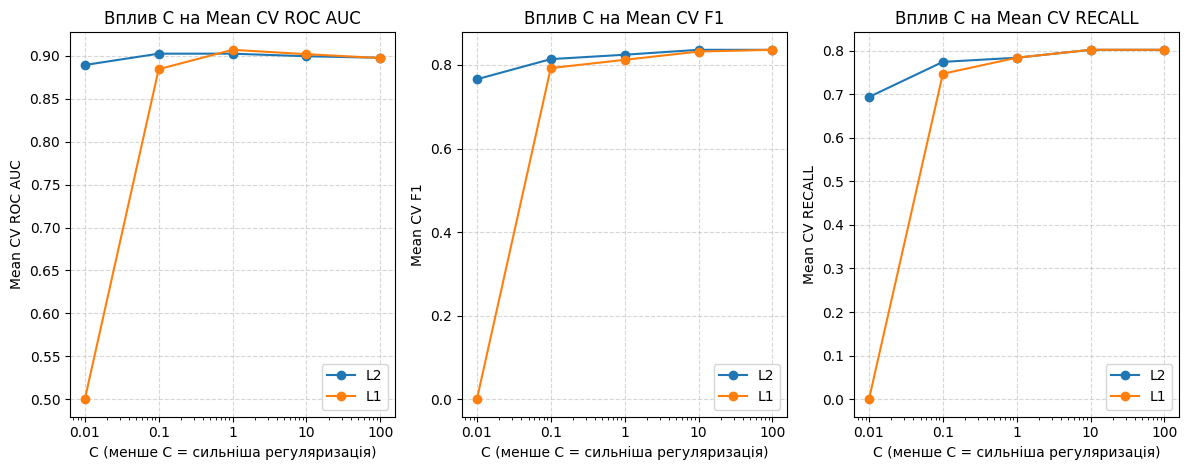

In [190]:
from sklearn.model_selection import GridSearchCV

c_values = [0.01, 0.1, 1, 10, 100]

reg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=5000, random_state=42)),
])

param_grid = [
    {
        "classifier__penalty": ["l2"],
        "classifier__solver": ["lbfgs"],
        "classifier__C": c_values,
    },
    {
        "classifier__penalty": ["l1"],
        "classifier__solver": ["liblinear"],
        "classifier__C": c_values,
    },
]

grid_search = GridSearchCV(
    estimator=reg_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring={"roc_auc": "roc_auc", "f1": "f1", "recall": "recall"},
    refit="recall",
    return_train_score=False,
)

grid_search.fit(X_train, y_train)

# Охайна таблиця результатів CV для всіх комбінацій penalty та C
cv_reg_df = pd.DataFrame({
    "penalty": grid_search.cv_results_["param_classifier__penalty"],
    "solver": grid_search.cv_results_["param_classifier__solver"],
    "C": grid_search.cv_results_["param_classifier__C"].astype(float),
    "mean_cv_roc_auc": grid_search.cv_results_["mean_test_roc_auc"].round(4),
    "std_cv_roc_auc": grid_search.cv_results_["std_test_roc_auc"].round(4),
    "mean_cv_f1": grid_search.cv_results_["mean_test_f1"].round(4),
    "std_cv_f1": grid_search.cv_results_["std_test_f1"].round(4),
    "mean_cv_recall": grid_search.cv_results_["mean_test_recall"].round(4),
    "std_cv_recall": grid_search.cv_results_["std_test_recall"].round(4),
}).sort_values(["penalty", "C"]).reset_index(drop=True)

print("=== Результати CV для L1 і L2 при різних C ===")
print(cv_reg_df.to_string(index=False))

print("\nНайкраща конфігурація за CV:", grid_search.best_params_)
print(f"Найкращий середній CV F1: {grid_search.best_score_:.4f}")

# Графік впливу C на середню CV ROC AUC та середню CV F1
fig, axes = plt.subplots(1, 3, figsize=(12, 4.8))

metrics_to_plot = [
    ("mean_cv_roc_auc", "Mean CV ROC AUC"),
    ("mean_cv_f1", "Mean CV F1"),
    ("mean_cv_recall", "Mean CV RECALL"),
]

for ax, (col_name, y_label) in zip(axes, metrics_to_plot):
    for pen in ["l2", "l1"]:
        sub = cv_reg_df[cv_reg_df["penalty"] == pen].sort_values("C")
        ax.plot(
            sub["C"],
            sub[col_name],
            marker="o",
            label=pen.upper(),
        )
    ax.set_xscale("log")
    ax.set_xticks(c_values)
    ax.set_xticklabels([str(c) for c in c_values])
    ax.set_xlabel("C (менше C = сильніша регуляризація)")
    ax.set_ylabel(y_label)
    ax.set_title(f"Вплив C на {y_label}")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

=== Результати CV для L1 і L2 при різних C ===
penalty    solver    C  mean_cv_roc_auc  std_cv_roc_auc  mean_cv_f1  std_cv_f1  mean_cv_recall  std_cv_recall
     l1 liblinear  1.0           0.9070          0.0114      0.8123     0.0173          0.7834         0.0677
     l1 liblinear  2.0           0.9039          0.0119      0.8220     0.0123          0.7925         0.0554
     l1 liblinear  3.0           0.9033          0.0112      0.8329     0.0188          0.8103         0.0543
     l1 liblinear  4.0           0.9040          0.0112      0.8277     0.0231          0.8012         0.0480
     l1 liblinear  5.0           0.9030          0.0112      0.8335     0.0186          0.8103         0.0359
     l1 liblinear  6.0           0.9019          0.0106      0.8335     0.0186          0.8103         0.0359
     l1 liblinear  7.0           0.9019          0.0106      0.8371     0.0125          0.8103         0.0359
     l1 liblinear  8.0           0.9019          0.0096      0.8321     0

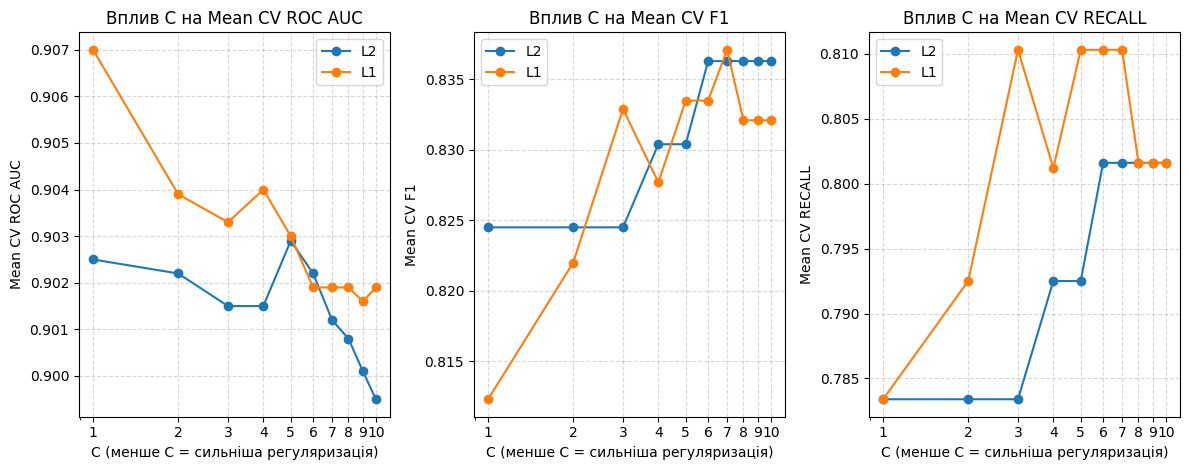

In [191]:
c_values = list(range(1,11))

param_grid = [
    {
        "classifier__penalty": ["l2"],
        "classifier__solver": ["lbfgs"],
        "classifier__C": c_values,
    },
    {
        "classifier__penalty": ["l1"],
        "classifier__solver": ["liblinear"],
        "classifier__C": c_values,
    },
]

grid_search = GridSearchCV(
    estimator=reg_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring={"roc_auc": "roc_auc", "f1": "f1", "recall": "recall"},
    refit="recall",
    return_train_score=False,
)

grid_search.fit(X_train, y_train)

# Охайна таблиця результатів CV для всіх комбінацій penalty та C
cv_reg_df = pd.DataFrame({
    "penalty": grid_search.cv_results_["param_classifier__penalty"],
    "solver": grid_search.cv_results_["param_classifier__solver"],
    "C": grid_search.cv_results_["param_classifier__C"].astype(float),
    "mean_cv_roc_auc": grid_search.cv_results_["mean_test_roc_auc"].round(4),
    "std_cv_roc_auc": grid_search.cv_results_["std_test_roc_auc"].round(4),
    "mean_cv_f1": grid_search.cv_results_["mean_test_f1"].round(4),
    "std_cv_f1": grid_search.cv_results_["std_test_f1"].round(4),
    "mean_cv_recall": grid_search.cv_results_["mean_test_recall"].round(4),
    "std_cv_recall": grid_search.cv_results_["std_test_recall"].round(4),
}).sort_values(["penalty", "C"]).reset_index(drop=True)

print("=== Результати CV для L1 і L2 при різних C ===")
print(cv_reg_df.to_string(index=False))

print("\nНайкраща конфігурація за CV:", grid_search.best_params_)
print(f"Найкращий середній CV RECALL: {grid_search.best_score_:.4f}")

# Графік впливу C на середню CV ROC AUC та середню CV F1
fig, axes = plt.subplots(1, 3, figsize=(12, 4.8))

metrics_to_plot = [
    ("mean_cv_roc_auc", "Mean CV ROC AUC"),
    ("mean_cv_f1", "Mean CV F1"),
    ("mean_cv_recall", "Mean CV RECALL"),
]

for ax, (col_name, y_label) in zip(axes, metrics_to_plot):
    for pen in ["l2", "l1"]:
        sub = cv_reg_df[cv_reg_df["penalty"] == pen].sort_values("C")
        ax.plot(
            sub["C"],
            sub[col_name],
            marker="o",
            label=pen.upper(),
        )
    ax.set_xscale("log")
    ax.set_xticks(c_values)
    ax.set_xticklabels([str(c) for c in c_values])
    ax.set_xlabel("C (менше C = сильніша регуляризація)")
    ax.set_ylabel(y_label)
    ax.set_title(f"Вплив C на {y_label}")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

**Перевірка за F1**

В результаті пдбору, маємо найкращий результат за С=7 при регуляризації Л1

Найкраща конфігурація за CV: {'classifier__C': 7, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}

Найкращий середній CV F1: 0.8371

**Перевірка за Recall**

В результаті пдбору, маємо найкращий результат за С=3 при регуляризації Л1

Найкраща конфігурація за CV: {'classifier__C': 3, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}

Найкращий середній CV Recall: 0.8103

**З одного боку результати різні, але якщо поглянути і на F1 і на Recall, то С=7 влаштоує, адже Recall однаковий що при С=3, що при С=7, а F1 краще при С=7**

In [192]:
# 1. Збираємо та навчаємо найкращий пайплайн за CV на тренувальній вибірці
best_model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        LogisticRegression(
            C=7,
            penalty="l1",
            solver="liblinear",
            max_iter=5000,
            random_state=42,
        ),
    ),
])

best_model_pipeline.fit(X_train, y_train)

# 2. Отримуємо назви всіх ознак після OneHotEncoder та ColumnTransformer
fitted_preprocessor = best_model_pipeline.named_steps["preprocessor"]
fitted_classifier = best_model_pipeline.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefs = fitted_classifier.coef_[0]

# 3. Формуємо таблицю коефіцієнтів та їхніх модулів
coef_df = (
    pd.DataFrame({
        "feature": feature_names,
        "coef": coefs,
        "abs_coef": np.abs(coefs),
        "effect_on_log_odds": np.where(
            coefs > 0,
            "збільшує (+)",
            np.where(coefs < 0, "зменшує (-)", "0.0 (занулено L1)"),
        ),
    })
    .sort_values("abs_coef", ascending=False)
    .reset_index(drop=True)
)

print("=== Усі ознаки, відсортовані за модулем коефіцієнта ===")
print(coef_df.to_string(index=False))

top5_features = coef_df.head(5)
print("\n=== Топ-5 ознак із найбільшими за модулем коефіцієнтами ===")
print(top5_features.to_string(index=False))

zeroed_count = int((coef_df["coef"] == 0).sum())
print(f"\nКількість занулених коефіцієнтів (L1): {zeroed_count} із {len(coef_df)}")

=== Усі ознаки, відсортовані за модулем коефіцієнта ===
         feature      coef  abs_coef effect_on_log_odds
     cat__ca_0.0 -2.171002  2.171002        зменшує (-)
   cat__thal_7.0  1.468012  1.468012       збільшує (+)
     cat__cp_4.0  1.327758  1.327758       збільшує (+)
    cat__sex_0.0 -1.292649  1.292649        зменшує (-)
  cat__slope_2.0  1.022705  1.022705       збільшує (+)
     cat__cp_1.0 -0.715867  0.715867        зменшує (-)
     cat__cp_3.0 -0.529091  0.529091        зменшує (-)
     cat__ca_2.0  0.512481  0.512481       збільшує (+)
  cat__exang_0.0 -0.467150  0.467150        зменшує (-)
     cat__ca_3.0  0.435366  0.435366       збільшує (+)
     cat__cp_2.0  0.419305  0.419305       збільшує (+)
   num__trestbps  0.415355  0.415355       збільшує (+)
    num__thalach -0.381193  0.381193        зменшує (-)
    cat__sex_1.0  0.377177  0.377177       збільшує (+)
cat__restecg_2.0  0.366253  0.366253       збільшує (+)
  cat__slope_1.0 -0.305601  0.305601        змен

#ЧАСТИНА II. ПРАКТИЧНА РОБОТА 5
##k-NN та ймовірнісні методи класифікації

##Мета практичної роботи
###Дослідити вплив масштабу та гіперпараметрів на k-NN, побудувати Gaussian Naive Bayes,LDA і QDA та коректно порівняти їх за однаковою схемою крос-валідації.

In [193]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

In [194]:
knn_model_pipeline = Pipeline([
("preprocessor", preprocessor),
("classifier", KNeighborsClassifier())
])
knn_model_pipeline_no_scaler = Pipeline([
("preprocessor", preprocessor_no_scaler),
("classifier", KNeighborsClassifier())
])

In [195]:
def test_cv(cv_model, with_scale:bool):
  if (with_scale):
    print("З маштабуанням")
  else:
    print("Без маштабуання")
  for metric in scoring:
    mean_score = cv_model[f"test_{metric}"].mean()
    std_score = cv_model[f"test_{metric}"].std()
    print(f"{metric}: {mean_score:.4f} (+/- {std_score:.4f})")

In [196]:
knn_results = cross_validate(
    knn_model_pipeline, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False
)
knn_results_no_scaler = cross_validate(
    knn_model_pipeline_no_scaler, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False
)

test_cv(knn_results, with_scale=True)
test_cv(knn_results_no_scaler, False)


З маштабуанням
accuracy: 0.8222 (+/- 0.0288)
precision: 0.8232 (+/- 0.0311)
recall: 0.7826 (+/- 0.0893)
f1: 0.7989 (+/- 0.0426)
roc_auc: 0.8712 (+/- 0.0387)
Без маштабуання
accuracy: 0.5742 (+/- 0.0234)
precision: 0.5417 (+/- 0.0272)
recall: 0.4866 (+/- 0.0181)
f1: 0.5120 (+/- 0.0134)
roc_auc: 0.6419 (+/- 0.0319)


Ознаки з великим числовим діапазоном домінують під час
обчислення відстані бо цей метод математично рахує вівдстань в просторі. За таких обставин при великих числах деякі ознаки будуть сильно домінувати і навііть нееликий шум може сильно повплиати на результат. Модель стає чутливою.


KNN (1):
F1 score: 0.7524 (+/- 0.0528)
ROC AUC:  0.7767
RECALL:   0.7372

KNN (3):
F1 score: 0.8042 (+/- 0.0272)
ROC AUC:  0.8709
RECALL:   0.8008

KNN (5):
F1 score: 0.7989 (+/- 0.0426)
ROC AUC:  0.8712
RECALL:   0.7826

KNN (7):
F1 score: 0.7942 (+/- 0.0184)
ROC AUC:  0.8721
RECALL:   0.7656

KNN (9):
F1 score: 0.7872 (+/- 0.0294)
ROC AUC:  0.8744
RECALL:   0.7557

KNN (11):
F1 score: 0.7791 (+/- 0.0273)
ROC AUC:  0.8806
RECALL:   0.7375

KNN (15):
F1 score: 0.7651 (+/- 0.0246)
ROC AUC:  0.8729
RECALL:   0.7209
Кращий результат по F1: 0.8041685405854828 при k=3
Кращий результат по ROC AUC: 0.8805744175309392 при k=11
Кращий результат по RECALL: 0.8007905138339921 при k=3


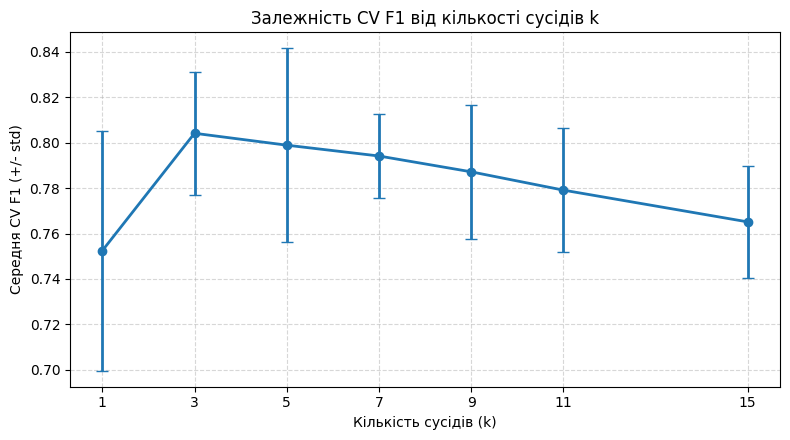

In [197]:
K_s = [1, 3, 5, 7, 9, 11, 15]

best_f1_k = 0
best_f1 = 0
best_roc_auc_k = 0
best_roc_auc = 0
best_recall_k = 0
best_recall = 0

f1_means = []
f1_stds = []
recall_means = []

for k in K_s:
  knn_model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=k))
])
  knn_results = cross_validate(
    knn_model_pipeline, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False
)
  F1_score = knn_results["test_f1"].mean()
  F1_std = knn_results["test_f1"].std()
  ROC_AUC_score = knn_results["test_roc_auc"].mean()
  RECALL_score = knn_results["test_recall"].mean()

  f1_means.append(F1_score)
  f1_stds.append(F1_std)
  recall_means.append(RECALL_score)

  print(f"\nKNN ({k}):")
  print(f"F1 score: {F1_score:.4f} (+/- {F1_std:.4f})")
  print(f"ROC AUC:  {ROC_AUC_score:.4f}")
  print(f"RECALL:   {RECALL_score:.4f}")
  if (F1_score > best_f1):
    best_f1 = F1_score
    best_f1_k = k
  if (ROC_AUC_score > best_roc_auc):
    best_roc_auc = ROC_AUC_score
    best_roc_auc_k = k
  if (RECALL_score > best_recall):
    best_recall = RECALL_score
    best_recall_k = k

print(f"Кращий результат по F1: {best_f1} при k={best_f1_k}")
print(f"Кращий результат по ROC AUC: {best_roc_auc} при k={best_roc_auc_k}")
print(f"Кращий результат по RECALL: {best_recall} при k={best_recall_k}")

plt.figure(figsize=(8, 4.5))
plt.errorbar(K_s, f1_means, yerr=f1_stds, marker="o", capsize=4, linewidth=2)
plt.xticks(K_s)
plt.xlabel("Кількість сусідів (k)")
plt.ylabel("Середня CV F1 (+/- std)")
plt.title("Залежність CV F1 від кількості сусідів k")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


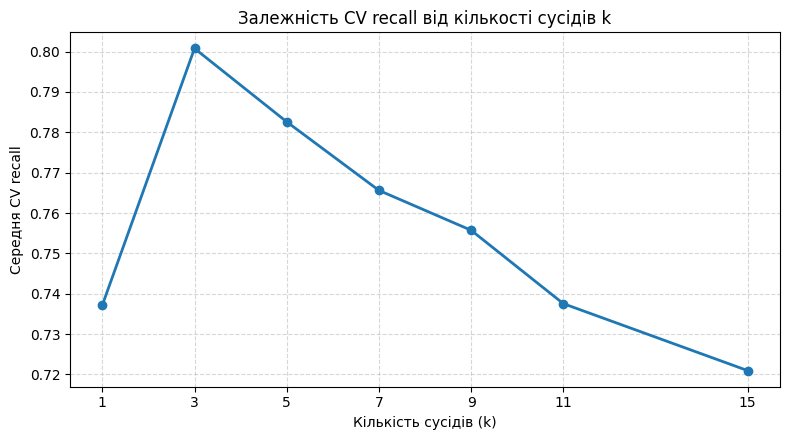

In [198]:
plt.figure(figsize=(8, 4.5))
plt.errorbar(K_s, recall_means, marker="o", capsize=4, linewidth=2)
plt.xticks(K_s)
plt.xlabel("Кількість сусідів (k)")
plt.ylabel("Середня CV recall")
plt.title("Залежність CV recall від кількості сусідів k")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Спочатку я порівнював за F1 і ROC AUC. Я побачив що рзультати відрізняються не сильно, але трішки кращий ROC AUC при k=11 та при k=11 нижче F1, показники не дають зрозумілий висновок, тому спробував перевірити важливу на мою думку метрику RECALL, і стало помітно що реколл найкращий при k=3. Тому k=3 оберу як найкраще значення

Вже після дослідження я вирішив перевірити що ж буде при 1му сусіду, але там (як і очікувалось) результат значно гірше

In [199]:
best_k = 3

In [200]:
def for_comparing_models(pipeline):
  res = cross_validate(
    pipeline, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False
  )
  F1_score = res["test_f1"].mean()
  F1_std = res["test_f1"].std()
  ROC_AUC_score = res["test_roc_auc"].mean()
  RECALL_score = res["test_recall"].mean()

  print(f"F1 score: {F1_score:.4f} (+/- {F1_std:.4f})")
  print(f"ROC AUC:  {ROC_AUC_score:.4f}")
  print(f"RECALL:   {RECALL_score:.4f}")

In [201]:
knn_model_pipeline_ecld = Pipeline([
  ("preprocessor", preprocessor),
  ("classifier", KNeighborsClassifier(n_neighbors=best_k, metric="euclidean"))
])
knn_model_pipeline_mnht = Pipeline([
  ("preprocessor", preprocessor),
  ("classifier", KNeighborsClassifier(n_neighbors=best_k, metric="manhattan"))
])


print("Евклідова")
for_comparing_models(knn_model_pipeline_ecld)
print("\nМангетенська")
for_comparing_models(knn_model_pipeline_mnht)

Евклідова
F1 score: 0.8042 (+/- 0.0272)
ROC AUC:  0.8709
RECALL:   0.8008

Мангетенська
F1 score: 0.8175 (+/- 0.0304)
ROC AUC:  0.8768
RECALL:   0.7917


З одного боку показник F1 краще для випадку з мангетенською довжиною, але я вважаю RECALL пріорітетнішим, тому скажу що краще пдходить мангетенська відстань

In [202]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import cross_val_predict, cross_validate
from sklearn.naive_bayes import GaussianNB

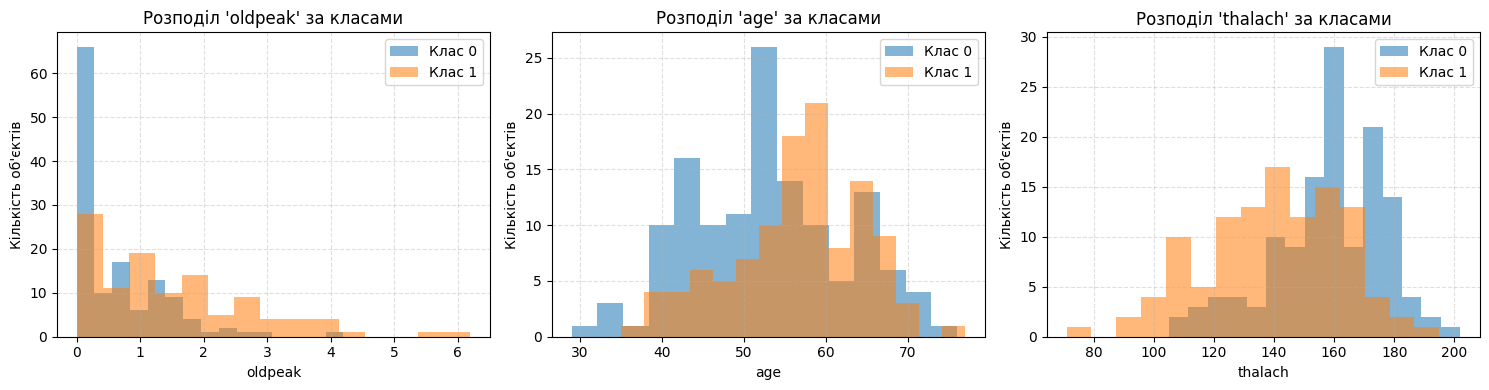

In [203]:
rnd = np.random.default_rng(42)
rnd = np.random.default_rng(42)
randoms = rnd.choice(len(numeric_columns), size=3, replace=False)
features_to_plot = [numeric_columns[randoms[0]], numeric_columns[randoms[1]], numeric_columns[randoms[2]]]

fig, axes = plt.subplots(1, len(features_to_plot), figsize=(5 * len(features_to_plot), 4))

for ax, col in zip(axes, features_to_plot):
    vals_0 = X_train.loc[y_train == 0, col].dropna()
    vals_1 = X_train.loc[y_train == 1, col].dropna()

    ax.hist(vals_0, bins=15, alpha=0.55, label="Клас 0")
    ax.hist(vals_1, bins=15, alpha=0.55, label="Клас 1")

    ax.set_title(f"Розподіл '{col}' за класами")
    ax.set_xlabel(col)
    ax.set_ylabel("Кількість об'єктів")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [204]:
gaussian_pipeline = Pipeline([
  ("preprocessor", preprocessor),
  ("classifier", GaussianNB())
])
lda_pipeline = Pipeline([
  ("preprocessor", preprocessor),
  ("classifier", LinearDiscriminantAnalysis())
])
qda_pipeline = Pipeline([
  ("preprocessor", preprocessor),
  ("classifier", QuadraticDiscriminantAnalysis())
])


print("GaussianNB")
for_comparing_models(gaussian_pipeline)
print("\nLDA")
for_comparing_models(lda_pipeline)
print("\nQDA")
for_comparing_models(qda_pipeline)

GaussianNB
F1 score: 0.7495 (+/- 0.0215)
ROC AUC:  0.8773
RECALL:   0.8458

LDA
F1 score: 0.8128 (+/- 0.0257)
ROC AUC:  0.8993
RECALL:   0.7656

QDA


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

F1 score: 0.5709 (+/- 0.1433)
ROC AUC:  0.7607
RECALL:   0.8186


In [205]:
prms = [0.01, 0.1, 0.25, 0.5, 1]

for prm in prms:
  qda_pipeline = Pipeline([
  ("preprocessor", preprocessor),
  ("classifier", QuadraticDiscriminantAnalysis(reg_param=prm))
])
  print(f"\nQDA reg_param={prm}")
  for_comparing_models(qda_pipeline)


QDA reg_param=0.01
F1 score: 0.7709 (+/- 0.0440)
ROC AUC:  0.8343
RECALL:   0.7743

QDA reg_param=0.1
F1 score: 0.7962 (+/- 0.0271)
ROC AUC:  0.8680
RECALL:   0.7743

QDA reg_param=0.25
F1 score: 0.7921 (+/- 0.0322)
ROC AUC:  0.8805
RECALL:   0.7561

QDA reg_param=0.5
F1 score: 0.7988 (+/- 0.0286)
ROC AUC:  0.8883
RECALL:   0.7561

QDA reg_param=1
F1 score: 0.7717 (+/- 0.0447)
ROC AUC:  0.8718
RECALL:   0.7383


Згдно з гістограмами гаусівський наївний баяс буде працювати, але не дально (2 з 3 ознак - за нормальним розподлом)

Результати LDA - значно кращий F1, але оскільки я надаю переагу recall, то тут GaussianNB краще

QDA при регулюванні 0.1 кращее за LDA(по реколу, ф1 залишається гіршим), але програє GaussianNB, де recall = 0.8458 (в QDA recall = 0.7743)

In [206]:
best_reg_param = 0.1
qda_pipeline = Pipeline([
  ("preprocessor", preprocessor),
  ("classifier", QuadraticDiscriminantAnalysis(reg_param=best_reg_param))
])

In [207]:

oof_gnb = cross_val_predict(
    gaussian_pipeline, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]
oof_lda = cross_val_predict(
    lda_pipeline, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]
oof_qda = cross_val_predict(
    qda_pipeline, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

oof_df = pd.DataFrame(
    {
        "Об'єкт train": X_train.index,
        "Справжній клас": y_train.values,
        "GaussianNB OOF": oof_gnb,
        "LDA OOF": oof_lda,
        "QDA OOF": oof_qda,
    }
)


idx_0 = oof_df[oof_df["Справжній клас"] == 0].head(3).index
idx_1 = oof_df[oof_df["Справжній клас"] == 1].head(3).index
sample_oof = oof_df.loc[idx_0.union(idx_1)].round(4)

print(sample_oof.to_string(index=False))

 Об'єкт train  Справжній клас  GaussianNB OOF  LDA OOF  QDA OOF
          180               1          1.0000   0.9039   0.6115
          208               0          0.0000   0.0220   0.0075
          167               0          0.0000   0.4726   0.2175
          105               0          0.4342   0.1608   0.0369
          297               1          1.0000   0.6167   0.6750
          120               1          1.0000   0.9787   0.9980


#ЧАСТИНА III. ПРАКТИЧНА РОБОТА 6
##Метод опорних векторів і пошук гіперпараметрів

##Мета практичної роботи
###Побудувати лінійну та RBF-SVM, дослідити параметри C і gamma та виконати коректний пошук гіперпараметрів лише на навчальній вибірці.

In [208]:
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.svm import SVC

In [209]:
C_s = [0.1, 1, 10]

for c in C_s:
  svm_pipeline = Pipeline([
  ("preprocessor", preprocessor),
  ("classifier", SVC(kernel="linear", C=c))
  ])
  print(f"\nЛінійна SVM з параметром c={c}")
  for_comparing_models(svm_pipeline)



Лінійна SVM з параметром c=0.1
F1 score: 0.7962 (+/- 0.0536)
ROC AUC:  0.9047
RECALL:   0.7375

Лінійна SVM з параметром c=1
F1 score: 0.8025 (+/- 0.0309)
ROC AUC:  0.8980
RECALL:   0.7747

Лінійна SVM з параметром c=10
F1 score: 0.8000 (+/- 0.0263)
ROC AUC:  0.8968
RECALL:   0.7747


Найкращий результат трапляється при с = 1

In [210]:
param_grid = [
{
"classifier__kernel": ["linear"],
"classifier__C": [0.1, 1, 10]
},
{
"classifier__kernel": ["rbf"],
"classifier__C": [0.1, 1, 10],
"classifier__gamma": ["scale", 0.01, 0.1]
}
]

=== Результати CV для SVM ===
kernel gamma    C  mean_cv_roc_auc  std_cv_roc_auc  mean_cv_f1  std_cv_f1  mean_cv_recall  std_cv_recall
linear     -  0.1           0.9047          0.0195      0.7962     0.0536          0.7375         0.0986
linear     -  1.0           0.8980          0.0149      0.8025     0.0309          0.7747         0.0644
linear     - 10.0           0.8968          0.0109      0.8000     0.0263          0.7747         0.0408
   rbf  0.01  0.1           0.8821          0.0352      0.2461     0.1129          0.1451         0.0733
   rbf  0.01  1.0           0.8957          0.0254      0.7951     0.0292          0.7561         0.0564
   rbf  0.01 10.0           0.8968          0.0184      0.8270     0.0330          0.7830         0.0683
   rbf   0.1  0.1           0.8848          0.0313      0.7652     0.0174          0.7028         0.0206
   rbf   0.1  1.0           0.8867          0.0252      0.7893     0.0271          0.7648         0.0797
   rbf   0.1 10.0        

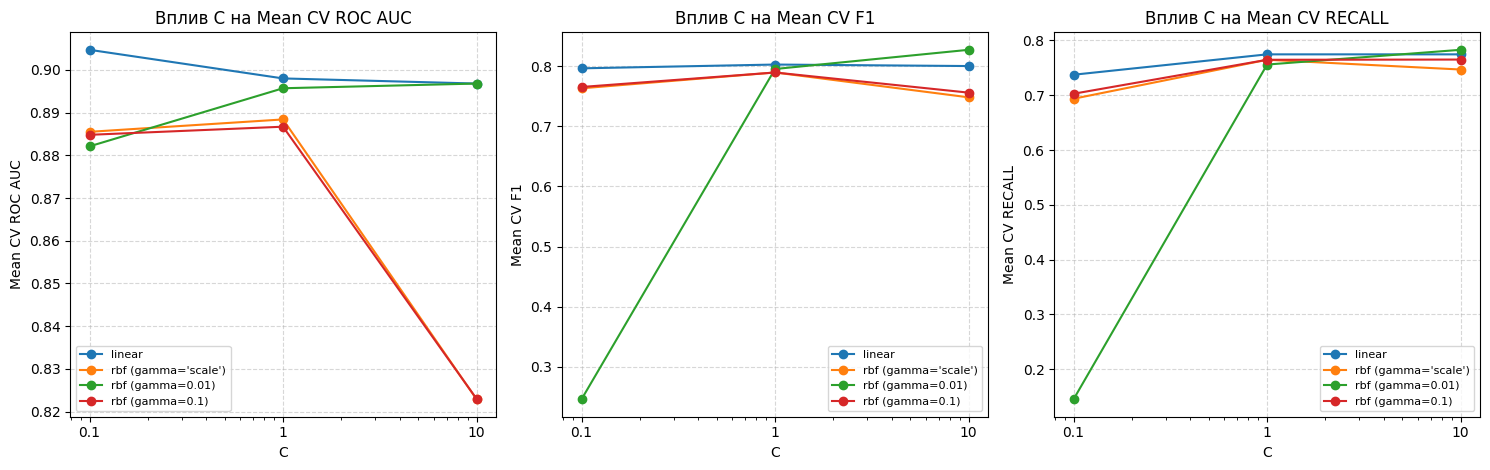

In [215]:
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring={"roc_auc": "roc_auc", "f1": "f1", "recall": "recall"},
    refit="recall",
    return_train_score=False,
)

grid_search.fit(X_train, y_train)

results = grid_search.cv_results_
gamma_clean = [
    "-" if (k == "linear" or pd.isna(g)) else str(g)
    for k, g in zip(results["param_classifier__kernel"], results["param_classifier__gamma"])
]

cv_svm_df = pd.DataFrame({
    "kernel": results["param_classifier__kernel"],
    "gamma": gamma_clean,
    "C": results["param_classifier__C"].astype(float),
    "mean_cv_roc_auc": np.round(results["mean_test_roc_auc"], 4),
    "std_cv_roc_auc": np.round(results["std_test_roc_auc"], 4),
    "mean_cv_f1": np.round(results["mean_test_f1"], 4),
    "std_cv_f1": np.round(results["std_test_f1"], 4),
    "mean_cv_recall": np.round(results["mean_test_recall"], 4),
    "std_cv_recall": np.round(results["std_test_recall"], 4),
}).sort_values(["kernel", "gamma", "C"]).reset_index(drop=True)

print("=== Результати CV для SVM ===")
print(cv_svm_df.to_string(index=False))

top_configs = cv_svm_df.sort_values("mean_cv_recall", ascending=False).head(5)
print("\n=== Топ-5 конфігурацій за середнім CV RECALL ===")
print(top_configs.to_string(index=False))

print("\nНайкраща конфігурація за CV:", grid_search.best_params_)
print(f"Найкращий середній CV результат ({grid_search.refit}): {grid_search.best_score_:.4f}")

# Графіки впливу C для лінійного ядра та RBF з різними gamma
c_values = [0.1, 1, 10]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

metrics_to_plot = [
    ("mean_cv_roc_auc", "Mean CV ROC AUC"),
    ("mean_cv_f1", "Mean CV F1"),
    ("mean_cv_recall", "Mean CV RECALL"),
]

curves = [
    ("linear", "-", "linear"),
    ("rbf", "scale", "rbf (gamma='scale')"),
    ("rbf", "0.01", "rbf (gamma=0.01)"),
    ("rbf", "0.1", "rbf (gamma=0.1)"),
]

for ax, (col_name, y_label) in zip(axes, metrics_to_plot):
    for kern, gam, label_txt in curves:
        sub = cv_svm_df[
            (cv_svm_df["kernel"] == kern) & (cv_svm_df["gamma"] == gam)
        ].sort_values("C")
        ax.plot(sub["C"], sub[col_name], marker="o", label=label_txt)

    ax.set_xscale("log")
    ax.set_xticks(c_values)
    ax.set_xticklabels([str(c) for c in c_values])
    ax.set_xlabel("C")
    ax.set_ylabel(y_label)
    ax.set_title(f"Вплив C на {y_label}")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

OOF ROC AUC (best SVM): 0.8982


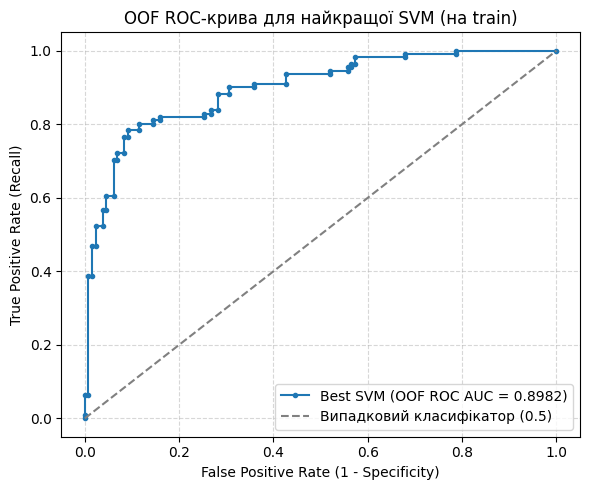

In [216]:
# Беремо найкращий пайплайн із GridSearchCV
best_svm = grid_search.best_estimator_

# Позавибіркові оцінки рішення для всіх об'єктів X_train (без X_test)
oof_scores = cross_val_predict(
    best_svm, X_train, y_train, cv=cv, method="decision_function"
)

# Оцінка ROC AUC та координати ROC-кривої
oof_roc_auc = roc_auc_score(y_train, oof_scores)
fpr, tpr, thresholds = roc_curve(y_train, oof_scores)

print(f"OOF ROC AUC (best SVM): {oof_roc_auc:.4f}")

# Побудова ROC-кривої
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, marker=".", label=f"Best SVM (OOF ROC AUC = {oof_roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Випадковий класифікатор (0.5)")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("OOF ROC-крива для найкращої SVM (на train)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Чим менше С, тим менше штраф за помилку, а отже модль допускає помилки. При великому С штраф також великий, і модель менше помиляється, але з'являється ризик переначання. gamma - описує як далеко точка вплиає на сусідів (чем менша гамма, тим далі вплиає)

**Найкраща конфігурація виходить при С = 10, gamma = 0.01, RBF ядро**

Найкраща конфігурація за CV: {'classifier__C': 10, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}

Найкращий середній CV результат (recall): 0.7830